In [1]:
import numpy as np 
import pandas as pd 

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt 
import seaborn as sns 

In [4]:
data = pd.read_csv("train.csv", usecols= ["Survived", "Age", "Fare"])
data.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [7]:
data.isnull().mean()*100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [8]:
x = data.drop(columns= ['Survived'])
y = data["Survived"]

In [11]:

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size= 0.2, random_state=2)

x_train.shape, x_test.shape

((712, 2), (179, 2))

# Random Imputation on Numerical Data

In [13]:
## So we are making new column and let the original be as it as to se the changes

x_train["Age_imputed"] = x_train["Age"]
x_test["Age_imputed"] = x_test["Age"]

In [14]:
x_train.head()

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0


In [15]:
x_test.head()

,Age,Fare,Age_imputed
707,42.0,26.2875,42.0
37,21.0,8.0500,21.0
615,24.0,65.0000,24.0
169,28.0,56.4958,28.0
68,17.0,7.9250,17.0


In [16]:
x_train["Age_imputed"][x_train["Age_imputed"].isnull()] = x_train["Age"].dropna().sample(x_train["Age"].isnull().sum()).values

x_test["Age_imputed"][x_test["Age_imputed"].isnull()] = x_test["Age"].dropna().sample(x_test["Age"].isnull().sum()).values


C:\Users\Asus\AppData\Local\Temp\ipykernel_7124\1462898322.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  x_train["Age_imputed"][x_train["Age_imputed"].isnull()] = x_train["Age"].dropna().sample(x_train["Age"].isnull().sum()).values
C:\

In [17]:
x_train["Age"].dropna().sample(x_train["Age"].isnull().sum()).values

array([44.  , 14.  , 51.  , 32.  , 27.  ,  2.  , 20.  , 49.  , 18.  ,
       50.  , 24.  , 16.  , 25.  , 62.  , 39.  , 21.  , 25.  , 49.  ,
       43.  , 33.  , 21.  , 14.5 , 39.  , 22.  , 25.  , 30.  , 34.  ,
       45.  , 27.  , 31.  , 57.  , 41.  , 36.  , 33.  , 23.  , 65.  ,
       29.  , 11.  , 19.  , 35.  , 66.  , 22.  , 22.  , 23.  , 40.  ,
       36.  , 45.5 , 71.  , 29.  , 39.  , 57.  , 36.  ,  9.  , 18.  ,
       54.  , 38.  , 36.  , 52.  , 24.  , 21.  , 19.  , 24.  , 24.  ,
       25.  , 16.  , 27.  , 27.  , 31.  ,  6.  , 19.  , 61.  , 10.  ,
       22.  , 22.  , 38.  , 19.  , 28.  , 19.  , 36.  , 59.  , 47.  ,
       47.  , 37.  , 22.  , 50.  , 21.  , 19.  , 22.  , 31.  , 36.  ,
        8.  , 20.  , 36.5 ,  4.  , 14.  , 16.  , 30.  ,  2.  , 27.  ,
       16.  , 21.  , 39.  , 36.  , 18.  , 30.  , 43.  , 26.  , 20.  ,
        1.  , 27.  , 21.  , 49.  , 34.  ,  2.  , 24.  , 28.  , 24.  ,
       45.  , 37.  , 41.  ,  1.  , 42.  , 27.  , 22.  , 24.  ,  0.42,
       48.  , 47.  ,

In [18]:
x_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,33.0
493,71.0,49.5042,71.0
527,NaN,221.7792,24.0


C:\Users\Asus\AppData\Local\Temp\ipykernel_7124\2454764907.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train["Age"], label= "Original", hist= False)
C:\Users\Asus\AppData\Local\Temp\ipykernel_7124\2454764907.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[

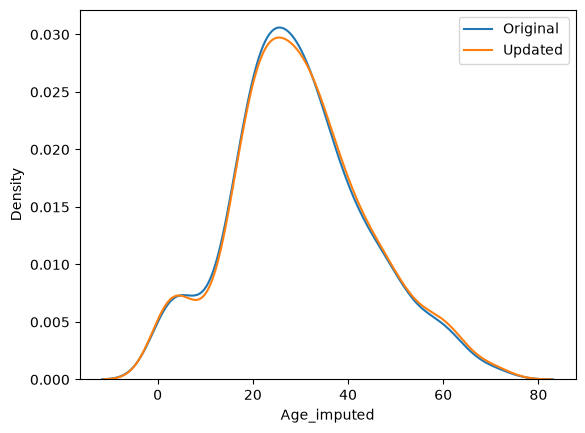

In [20]:
sns.distplot(x_train["Age"], label= "Original", hist= False)
sns.distplot(x_train["Age_imputed"], label= "Updated", hist= False)

plt.legend()
plt.show()

In [21]:
print("vARIANCE OF oRIGINAL aGE: ", x_train["Age"].var())
print("vARIANCE OF oRIGINAL aGE: ", x_train["Age_imputed"].var())


vARIANCE OF oRIGINAL aGE:  204.3495133904614
vARIANCE OF oRIGINAL aGE:  211.20966613568473


In [22]:
x_train[["Fare", "Age", "Age_imputed"]].cov()

,Fare,Age,Age_imputed
Fare,2368.246832,71.512440,54.533589
Age,71.512440,204.349513,204.349513
Age_imputed,54.533589,204.349513,211.209666


# Random Imputation on Categorical Data

In [26]:
data2 = pd.read_csv("house-train.csv", usecols=["GarageQual", "FireplaceQu", "SalePrice"])
data2.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [27]:
data2.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [28]:
x2 = data2
y2 = data2["SalePrice"]

In [29]:
x_train2, x_test2, y_train2, y_test2 = train_test_split(x2, y2, test_size=0.2, random_state= 2)

x_train2.shape, x_test2.shape

((1168, 3), (292, 3))

In [30]:
## Creating new columns for GarageQuality and FirePlaceQuality

x_train2["GarageQual_Imputed"] = x_train2["GarageQual"]
x_test2["GarageQual_Imputed"] = x_test2["GarageQual"]


x_train2["FireplaceQu_Imputed"] = x_train2["FireplaceQu"]
x_test2["FireplaceQu_Imputed"] = x_test2["FireplaceQu"]

In [32]:
x_train2.head()

,FireplaceQu,GarageQual,SalePrice,GarageQual_Imputed,FireplaceQu_Imputed
455,TA,TA,175500,TA,TA
863,NaN,TA,132500,TA,NaN
504,Fa,TA,147000,TA,Fa
1413,Gd,TA,257000,TA,Gd
1389,Gd,TA,131000,TA,Gd


In [33]:
## This code is to put random value in place of NaN

x_train2["GarageQual_imputed"][x_train2["GarageQual_imputed"].isnull()] = x_train2["GarageQual"].dropna().sample(x_train2["GarageQual"].isnull().sum()).values
x_test2["GarageQual_imputed"][x_test2["GarageQual_imputed"].isnull()] = x_test2["GarageQual"].dropna().sample(x_test2["GarageQual"].isnull().sum()).values

x_train2["FireplaceQu_imputed"][x_train2["FireplaceQu_imputed"].isnull()] = x_train2["FireplaceQu"].dropna().sample(x_train2["FireplaceQu"].isnull().sum()).values
x_test2["FireplaceQu_imputed"][x_test2["FireplaceQu_imputed"].isnull()] = x_test2["FireplaceQu"].dropna().sample(x_test2["FireplaceQu"].isnull().sum()).values



KeyError: 'GarageQual_imputed'